# Implementing Knowledge Distillation

This notebook walks through a complete implementation of knowledge distillation with working code examples. We'll build everything from scratch and train a real student model on MNIST.

The teacher is trained first and then frozen.
The distilled student is compared against a control student with the same architecture, initial weights, batch order and number of epochs, trained on the labels alone.
Choices are made on a validation split, and the test set is only read for the final comparison.

## Setup and Imports

In [1]:
import os
import platform
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.14.1+cpu


### Reproducibility

`SEED` fixes the validation split and the teacher, every student comparison is repeated for each entry of `SEEDS`.

In [2]:
SEED = 0
SEEDS = [0, 1, 2, 3, 4]
# deterministic kernels, so a rerun with the same seed gives the same numbers on this machine
torch.use_deterministic_algorithms(True)
# downloads land outside the repository, set KD_DATA_DIR to put them somewhere else
DATA_DIR = os.environ.get('KD_DATA_DIR', os.path.join(os.path.expanduser('~'), '.cache', 'kd-data'))

Library versions, hardware and seeds, for reproducing the numbers below.

In [3]:
print(f"python {platform.python_version()}, torch {torch.__version__}, numpy {np.__version__}, pandas {pd.__version__}")
print(f"platform: {platform.platform()}, {os.cpu_count()} logical cpus, torch threads: {torch.get_num_threads()}")
print(f"data and teacher seed: {SEED}, student seeds: {SEEDS}")

python 3.12.15, torch 2.14.1+cpu, numpy 2.5.4, pandas 3.0.6
platform: Windows-10-10.0.19045-SP0, 16 logical cpus, torch threads: 8
data and teacher seed: 0, student seeds: [0, 1, 2, 3, 4]


## Step 1: Temperature Scaling Function

Temperature controls how "smooth" the probability distribution becomes. Let's implement and test it:

In [4]:
def apply_temperature(logits, temperature):
    """
    temperature scaled softmax, the soft targets distillation trains on

    args:
        logits: raw model outputs before softmax
        temperature: higher gives a softer distribution, 1 is the ordinary softmax

    returns:
        softened probability distribution
    """
    return F.softmax(logits / temperature, dim=-1)

The softened distribution and its entropy at four temperatures.

In [5]:
# same example logits as notebook 01
logits = torch.tensor([10.0, 2.0, 1.0, 0.5])

print("temp scaling examples:")
print("="*60)
for T in [1, 3, 5, 10]:
    probs = apply_temperature(logits, temperature=T)
    print(f"\nT={T:2d}: {probs.numpy()}")
    print(f"Entropy: {-(probs * torch.log(probs)).sum():.4f} nats")

print("\nHigher temperature = Higher entropy = More of the teacher's ranking of the wrong classes is visible")

temp scaling examples:

T= 1: [9.9946660e-01 3.3528369e-04 1.2334397e-04 7.4811906e-05]
Entropy: 0.0050 nats

T= 3: [0.86101913 0.05982659 0.04286762 0.03628666]
Entropy: 0.5527 nats

T= 5: [0.6592983  0.13311003 0.10898128 0.09861033]
Entropy: 1.0131 nats

T=10: [0.44590312 0.20035718 0.18129069 0.17244904]
Entropy: 1.2949 nats

Higher temperature = Higher entropy = More of the teacher's ranking of the wrong classes is visible


## Step 2: The Distillation Loss Function

The core of knowledge distillation - combining soft targets from the teacher with hard labels:

In [6]:
def distillation_loss(student_logits, teacher_logits, labels, temperature=3.0, alpha=0.7):
    """
    knowledge distillation loss after hinton, vinyals and dean (2015)

    args:
        student_logits: raw outputs from the student
        teacher_logits: raw outputs from the frozen teacher
        labels: ground truth class indices
        temperature: softening parameter, above 1 exposes how the teacher ranks wrong classes (default: 3.0)
        alpha: weight on the distillation term, 1 - alpha goes to the label term (default: 0.7)

    returns:
        (total, distill, student) so the two terms can be logged separately
    """
    # kl_div expects the student as log probabilities and the teacher as probabilities
    soft_teacher = F.softmax(teacher_logits / temperature, dim=-1)
    soft_student = F.log_softmax(student_logits / temperature, dim=-1)

    # distillation term: kl(teacher_t || student_t), batchmean gives the per example kl
    # times t^2 because soft target gradients scale as 1 / t^2, this keeps both terms balanced as t changes
    distill_loss = F.kl_div(
        soft_student,
        soft_teacher,
        reduction='batchmean') * (temperature ** 2)

    # label term: ordinary cross entropy at t=1 against the ground truth
    student_loss = F.cross_entropy(student_logits, labels)

    total_loss = alpha * distill_loss + (1 - alpha) * student_loss

    return total_loss, distill_loss, student_loss

Check on random logits that the total is the weighted sum of the two terms.

In [7]:
# smoke test on random logits
torch.manual_seed(SEED)
dummy_student = torch.randn(4, 10)
dummy_teacher = torch.randn(4, 10)
dummy_labels = torch.randint(0, 10, (4,))

total, distill, student = distillation_loss(dummy_student, dummy_teacher, dummy_labels, temperature=3.0, alpha=0.7)

print("Testing Distillation Loss Function:")
print(f"Total Loss: {total:.4f}")
print(f"Distillation Loss: {distill:.4f} (weight: 0.7)")
print(f"Student Loss: {student:.4f} (weight: 0.3)")
print(f"\nVerify: {0.7*distill + 0.3*student:.4f} = {total:.4f}")

Testing Distillation Loss Function:
Total Loss: 1.4208
Distillation Loss: 0.9089 (weight: 0.7)
Student Loss: 2.6152 (weight: 0.3)

Verify: 1.4208 = 1.4208


## Step 3: Define Teacher and Student Models

Two MLPs for MNIST, both returning logits:

In [8]:
class TeacherModel(nn.Module):
    """large mlp teacher, about 13x the student's parameters"""
    def __init__(self, input_size=784, num_classes=10):
        super(TeacherModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.network(x)

The student keeps the input and output sizes with far fewer hidden units.

In [9]:
class StudentModel(nn.Module):
    """small mlp student, the model meant for deployment"""
    def __init__(self, input_size=784, num_classes=10):
        super(StudentModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)

Every model is built from an explicit seed.

In [10]:
def new_model(model_class, seed):
    # the seed fixes the initial weights, so a control and a distilled student can start identical
    torch.manual_seed(seed)
    return model_class().to(device)

Parameter counts of the two architectures.

In [11]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

teacher_params = count_parameters(TeacherModel())
student_params = count_parameters(StudentModel())

How much smaller the student is.

In [12]:
print("model architecture comparison:")
print(f"Teacher parameters: {teacher_params:,}")
print(f"Student parameters: {student_params:,}")
print(f"Compression ratio: {teacher_params/student_params:.1f}x")
print(f"Size reduction: {(1-student_params/teacher_params)*100:.1f}%")

model architecture comparison:
Teacher parameters: 1,462,538
Student parameters: 109,386
Compression ratio: 13.4x
Size reduction: 92.5%


Both architectures layer by layer.

In [13]:
print("Teacher Architecture:")
print(TeacherModel())
print("\nStudent Architecture:")
print(StudentModel())

Teacher Architecture:
TeacherModel(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)

Student Architecture:
StudentModel(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


## Step 4: Load MNIST

The images are flattened to 784 values and standardised with the usual MNIST mean and standard deviation.
6,000 training images are held out as a validation set.

In [14]:
def load_mnist(train):
    # the whole set fits in memory, so the tensors are built once instead of decoding images per batch
    raw = datasets.MNIST(DATA_DIR, train=train, download=True)
    x = (raw.data.float() / 255.0 - 0.1307) / 0.3081
    return x.view(len(x), -1), raw.targets.clone()

Load both splits and hold out the validation images.

In [15]:
train_X_full, train_y_full = load_mnist(train=True)
test_X, test_y = load_mnist(train=False)

perm = torch.randperm(len(train_X_full), generator=torch.Generator().manual_seed(SEED))
val_X, val_y = train_X_full[perm[:6000]], train_y_full[perm[:6000]]
train_X, train_y = train_X_full[perm[6000:]], train_y_full[perm[6000:]]

Training batches in a seeded order, validation and test in fixed batches of 1,000.

In [16]:
def make_train_loader(seed, batch_size=128):
    # a generator per run: the same seed gives the control and the distilled student the same batches
    return DataLoader(TensorDataset(train_X, train_y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

val_loader = DataLoader(TensorDataset(val_X, val_y), batch_size=1000)
test_loader = DataLoader(TensorDataset(test_X, test_y), batch_size=1000)

Split sizes.

In [17]:
print(f"Training samples: {len(train_X)}")
print(f"Validation samples: {len(val_X)}")
print(f"Test samples: {len(test_X)}")
print(f"Batches per epoch at batch size 128: {len(make_train_loader(SEED))}")

Training samples: 54000
Validation samples: 6000
Test samples: 10000
Batches per epoch at batch size 128: 422


## Step 5: Evaluation

Accuracy with dropout off, the argmax of the logits is the same at every temperature:

In [18]:
def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == batch_y).sum().item()
            total += batch_y.size(0)

    accuracy = 100 * correct / total
    return accuracy

## Step 6: Pre-train the Teacher Model

First, we need a well-trained teacher. Let's train it on the labels alone:

In [19]:
# plain supervised training on hard labels, reused below for the no distillation control
def train_supervised(model, train_loader, num_epochs=10, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)

    losses = []
    val_accs = []

    for epoch in range(num_epochs):
        model.train()
        epoch_loss = 0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = F.cross_entropy(outputs, batch_y)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        losses.append(epoch_loss / len(train_loader))
        val_accs.append(evaluate_model(model, val_loader))

    return losses, val_accs

Every model in this notebook trains for the same number of epochs.

In [20]:
num_epochs = 10

Train the teacher.

In [21]:
t0 = time.time()
teacher = new_model(TeacherModel, SEED)
teacher_losses, teacher_val_accs = train_supervised(teacher, make_train_loader(SEED), num_epochs=num_epochs)
print(f"teacher trained in {time.time() - t0:.0f} s")
print(f"teacher validation accuracy by epoch: {[round(a, 2) for a in teacher_val_accs]}")

teacher trained in 60 s
teacher validation accuracy by epoch: [95.45, 96.62, 96.83, 97.55, 97.67, 97.62, 97.72, 97.95, 97.62, 97.55]


Freeze it before any student sees it.

In [22]:
# freeze the teacher: eval mode turns its dropout off and no gradient will ever reach it
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

## Step 7: Train Student with Distillation

Now train the student model using knowledge distillation:

In [23]:
def train_student_distillation(student_model, teacher_model, train_loader, num_epochs=10, temperature=4.0, alpha=0.7, lr=0.001):
    """
    train the student on the frozen teacher's softened outputs plus the true labels
    """
    optimizer = optim.Adam(student_model.parameters(), lr=lr)
    teacher_model.eval()  # dropout off, so the soft targets are deterministic

    total_losses = []
    distill_losses = []
    label_losses = []
    val_accs = []

    for epoch in range(num_epochs):
        student_model.train()
        epoch_loss = 0
        epoch_distill = 0
        epoch_label = 0

        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)

            optimizer.zero_grad()

            # no_grad: the teacher is frozen, only the student's optimizer steps
            with torch.no_grad():
                teacher_logits = teacher_model(batch_X)

            student_logits = student_model(batch_X)

            total_loss, distill_loss, label_loss = distillation_loss(student_logits, teacher_logits, batch_y, temperature=temperature, alpha=alpha)

            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            epoch_distill += distill_loss.item()
            epoch_label += label_loss.item()

        total_losses.append(epoch_loss / len(train_loader))
        distill_losses.append(epoch_distill / len(train_loader))
        label_losses.append(epoch_label / len(train_loader))
        val_accs.append(evaluate_model(student_model, val_loader))

    return total_losses, distill_losses, label_losses, val_accs

`T = 4` and `alpha = 0.7` for this first run, the sweep below picks values on validation data.

In [24]:
temperature = 4.0
alpha = 0.7

Distill into the seed 0 student.

In [25]:
t0 = time.time()
student = new_model(StudentModel, SEED)
total_losses, distill_losses, label_losses, student_val_accs = train_student_distillation(
    student, teacher, make_train_loader(SEED), num_epochs=num_epochs, temperature=temperature, alpha=alpha)
print(f"distilled student trained in {time.time() - t0:.0f} s")

distilled student trained in 21 s


## Step 8: Train the Control Student

The same architecture, seed, batches and epochs, trained without the teacher:

In [26]:
t0 = time.time()
baseline_student = new_model(StudentModel, SEED)
baseline_losses, baseline_val_accs = train_supervised(baseline_student, make_train_loader(SEED), num_epochs=num_epochs)
print(f"control student trained in {time.time() - t0:.0f} s")

control student trained in 14 s


## Step 9: Visualize Training Progress

Validation accuracy of all three models, and how the distilled student's two loss terms evolved:

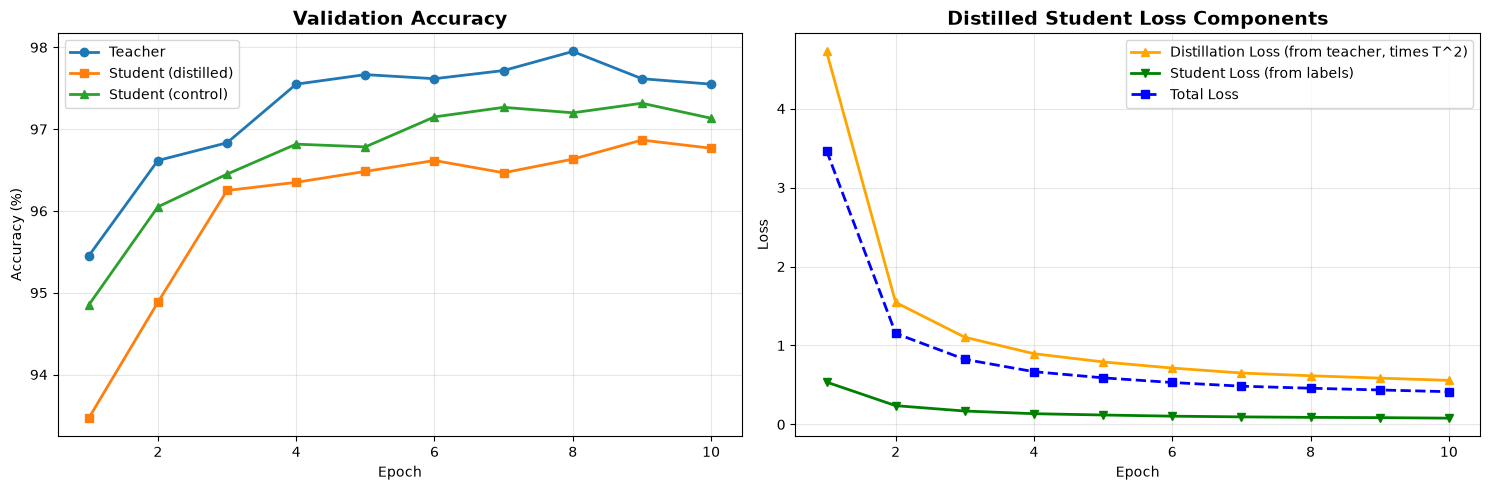

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epochs_axis = range(1, num_epochs + 1)

axes[0].plot(epochs_axis, teacher_val_accs, label='Teacher', marker='o', linewidth=2)
axes[0].plot(epochs_axis, student_val_accs, label='Student (distilled)', marker='s', linewidth=2)
axes[0].plot(epochs_axis, baseline_val_accs, label='Student (control)', marker='^', linewidth=2)
axes[0].set_title('Validation Accuracy', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_axis, distill_losses, label='Distillation Loss (from teacher, times T^2)',
             marker='^', linewidth=2, color='orange')
axes[1].plot(epochs_axis, label_losses, label='Student Loss (from labels)',
             marker='v', linewidth=2, color='green')
axes[1].plot(epochs_axis, total_losses, label='Total Loss',
             marker='s', linewidth=2, color='blue', linestyle='--')
axes[1].set_title('Distilled Student Loss Components', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 10: Hyperparameter Exploration

One factor at a time, so the effect of each can be read off: the temperature varies with `alpha = 0.7`, then `alpha` varies with `T = 4`.
Each setting is trained with three seeds and scored on the validation set.

In [28]:
SWEEP_SEEDS = SEEDS[:3]
configs = [(t, 0.7) for t in [1.0, 2.0, 4.0, 8.0]] + [(4.0, a) for a in [0.3, 0.5, 0.9]]

Train every setting with every sweep seed.

In [29]:
results = []
t0 = time.time()
for sweep_t, sweep_alpha in configs:
    for seed in SWEEP_SEEDS:
        test_student = new_model(StudentModel, seed)
        *_, val_accs = train_student_distillation(
            test_student, teacher, make_train_loader(seed),
            num_epochs=num_epochs, temperature=sweep_t, alpha=sweep_alpha)
        results.append({'Temperature': sweep_t, 'Alpha': sweep_alpha, 'Seed': seed,
                        'Validation Accuracy': val_accs[-1]})
print(f"{len(results)} sweep runs in {(time.time() - t0) / 60:.1f} min")

21 sweep runs in 7.3 min


Mean and standard deviation per setting.

In [30]:
df_results = (pd.DataFrame(results).groupby(['Temperature', 'Alpha'])['Validation Accuracy']
              .agg(['mean', 'std']).round(2).reset_index())
print("Validation accuracy (%), mean and std over 3 seeds:")
print(df_results.to_string(index=False))

Validation accuracy (%), mean and std over 3 seeds:
 Temperature  Alpha  mean  std
         1.0    0.7 97.14 0.20
         2.0    0.7 97.08 0.13
         4.0    0.3 97.02 0.15
         4.0    0.5 96.88 0.08
         4.0    0.7 96.73 0.14
         4.0    0.9 96.61 0.10
         8.0    0.7 96.46 0.15


Validation accuracy against each factor, error bars are one standard deviation over the seeds.

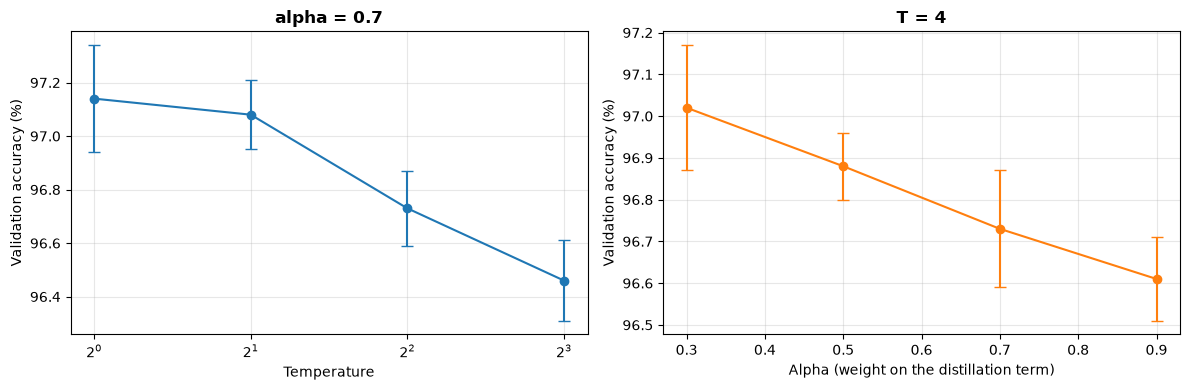

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_rows = df_results[df_results['Alpha'] == 0.7]
a_rows = df_results[df_results['Temperature'] == 4.0]
axes[0].errorbar(t_rows['Temperature'], t_rows['mean'], yerr=t_rows['std'], marker='o', capsize=4)
axes[0].set_xscale('log', base=2)
axes[0].set_title('alpha = 0.7', fontweight='bold')
axes[0].set_xlabel('Temperature')
axes[1].errorbar(a_rows['Alpha'], a_rows['mean'], yerr=a_rows['std'], marker='o', capsize=4, color='tab:orange')
axes[1].set_title('T = 4', fontweight='bold')
axes[1].set_xlabel('Alpha (weight on the distillation term)')
for ax in axes:
    ax.set_ylabel('Validation accuracy (%)')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The setting with the best mean validation accuracy is carried forward.

In [32]:
best = df_results.loc[df_results['mean'].idxmax()]
best_t, best_alpha = float(best['Temperature']), float(best['Alpha'])
print(f"Best configuration on validation: T = {best_t}, alpha = {best_alpha}")

Best configuration on validation: T = 1.0, alpha = 0.7


## Step 11: Five Seeds per Arm

The control and the distilled student with the selected setting, once per seed.
Within a seed both start from the same weights and see the same batches.

In [33]:
arms = {'control': [], 'distilled': []}
t0 = time.time()
for seed in SEEDS:
    control = new_model(StudentModel, seed)
    train_supervised(control, make_train_loader(seed), num_epochs=num_epochs)
    arms['control'].append(control)

    distilled = new_model(StudentModel, seed)
    train_student_distillation(distilled, teacher, make_train_loader(seed), num_epochs=num_epochs,
                               temperature=best_t, alpha=best_alpha)
    arms['distilled'].append(distilled)
print(f"{len(SEEDS) * 2} student runs in {(time.time() - t0) / 60:.1f} min")

10 student runs in 2.6 min


## Step 12: Evaluate and Compare Models

The test set is read here for the first time, once per model.

In [34]:
teacher_acc = evaluate_model(teacher, test_loader)
per_seed = pd.DataFrame({arm: [evaluate_model(m, test_loader) for m in models] for arm, models in arms.items()},
                        index=pd.Index(SEEDS, name='seed'))
per_seed['distilled - control'] = per_seed['distilled'] - per_seed['control']
print("Test accuracy (%) per seed:")
print(per_seed.round(2).to_string())

Test accuracy (%) per seed:
      control  distilled  distilled - control
seed                                         
0       97.72      97.66                -0.06
1       97.76      97.80                 0.04
2       97.57      97.82                 0.25
3       97.82      97.55                -0.27
4       97.89      97.82                -0.07


Mean and standard deviation of test accuracy per model.

In [35]:
def result_row(name, params, accs):
    accs = np.atleast_1d(accs)
    return {'Model': name, 'Parameters': params, 'Size (MB)': round(params * 4 / 1e6, 2), 'Runs': len(accs),
            'Test acc mean (%)': round(float(np.mean(accs)), 2),
            'Test acc std': round(float(np.std(accs, ddof=1)), 2) if len(accs) > 1 else float('nan')}

results_table = pd.DataFrame([
    result_row('Teacher', teacher_params, teacher_acc),
    result_row('Student, control', student_params, per_seed['control']),
    result_row(f'Student, distilled (T={best_t}, alpha={best_alpha})', student_params, per_seed['distilled']),
])
print(results_table.to_string(index=False))

                                Model  Parameters  Size (MB)  Runs  Test acc mean (%)  Test acc std
                              Teacher     1462538       5.85     1              97.96           NaN
                     Student, control      109386       0.44     5              97.75          0.12
Student, distilled (T=1.0, alpha=0.7)      109386       0.44     5              97.73          0.12


The two students share each seed, so the differences are paired, a paired t test says whether the mean difference stands out from seed noise.

In [36]:
diff = per_seed['distilled - control']
test = stats.ttest_rel(per_seed['distilled'], per_seed['control'])
print(f"Distilled minus control: {diff.mean():+.2f} +/- {diff.std(ddof=1):.2f} percentage points "
      f"(mean +/- std over {len(diff)} seeds), distilled ahead on {(diff > 0).sum()} of {len(diff)} seeds, "
      f"paired t test p = {test.pvalue:.3f}")
print(f"Compression: {teacher_params/student_params:.1f}x smaller")

Distilled minus control: -0.02 +/- 0.19 percentage points (mean +/- std over 5 seeds), distilled ahead on 2 of 5 seeds, paired t test p = 0.808
Compression: 13.4x smaller


## Key Takeaways

1. **The loss**: `alpha * T^2 * KL(teacher_T || student_T) + (1 - alpha) * CE(labels, student)`, computed on logits, with the teacher frozen.
2. **The control**: a distillation result only means something next to a student with the same architecture, seed, batches and epochs trained without the teacher.
3. **Validation, then test**: hyperparameters are chosen on held out training data, the test set is read once at the end.